# **Research Question:**
What is the optimal behaviour to minimise fatigue with reduced sleep?
<br>
<br>

### **Hypothesis**:
Reducing screentime, exercise before sleep, screen brightness, caffeine intake, and increasing sleep hours, and snoozes should help minimise fatigue.

<br>

This question is relevant because more and more younger students are having worse sleep, and sleep debt can result in poor cognitive performance, increased sleepiness, poor mood, and a higher risk for accidents. It also significantly affects academics. While we are often given advice on how to sleep better, I wondered which factors have the highest impact on next-day fatigue, as well as how to minimise it.


<br>

https://academic.oup.com/sleepadvances/article/4/1/zpac044/6854927
<br>
https://pmc.ncbi.nlm.nih.gov/articles/PMC10900033/

# Linear regression

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("bedtime_screentime_sleep_debt.csv")
display(df.head())

shape = df.shape
print(shape) # size of the dataset. 8500 rows means it's robust

names = df.columns
display(names)

# import dataset from Kaggle
# https://www.kaggle.com/datasets/samartalwar/sleep-debt-and-screen-time-late-night-phone-habits

,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
0,USR-00001,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0,21,84.4,3.20,23.5,22.2,7,10.0,Severe Sleep Debt
1,USR-00002,58,Female,Student,Intermediate,163,YouTube,76,1,92,72,86.7,4.06,18.0,21.5,7,10.0,Severe Sleep Debt
2,USR-00003,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45,23,70.5,3.20,18.1,20.5,7,10.0,Severe Sleep Debt
3,USR-00004,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97,49,38.1,6.99,21.6,22.4,1,1.7,Mild Deficit
4,USR-00005,23,Female,Healthcare / Shift Worker,Intermediate,27,TikTok / Reels,82,1,0,38,32.3,4.58,24.1,22.8,4,5.3,Moderate Debt


(8500, 18)


Index(['user_id', 'age', 'gender', 'occupation_type', 'chronotype',
       'bedtime_phone_minutes', 'primary_bedtime_app', 'screen_brightness_pct',
       'blue_light_filter_active', 'caffeine_post_5pm_mg',
       'physical_activity_min', 'sleep_latency_min', 'total_sleep_hours',
       'deep_sleep_pct', 'rem_sleep_pct', 'morning_alarm_snoozes',
       'next_day_fatigue_score', 'sleep_debt_category'],
      dtype='object')

In [2]:
# normalise datasets
def normalise_z(dfin, columns_means=None, columns_stds=None):
    if isinstance(dfin, pd.DataFrame):
        if columns_means is None:
            columns_means = dfin.mean(axis=0)
        if columns_stds is None:
            columns_stds = dfin.std(axis=0)
        dfout = (dfin - columns_means) / columns_stds

    elif isinstance(dfin, np.ndarray):
        if columns_means is None:
            columns_means = np.mean(dfin, axis=0)
        if columns_stds is None:
            columns_stds = np.std(dfin, axis=0)
        dfout = (dfin - columns_means) / columns_stds

    return dfout, columns_means, columns_stds

In [3]:
# make it easier to get features + targets cleanly
def get_features_targets(df, feature_names, target_names):
    df_feature = df.loc[:, feature_names]
    df_target = df.loc[:, target_names]
    return df_feature, df_target

In [4]:
# features + target
feature_cols = [
    'bedtime_phone_minutes',
    'screen_brightness_pct',
    'blue_light_filter_active',
    'caffeine_post_5pm_mg',
    'physical_activity_min',
    'sleep_latency_min',
    'total_sleep_hours',
    'deep_sleep_pct',
    'rem_sleep_pct',
    'morning_alarm_snoozes'
]
target_col = ['next_day_fatigue_score']

X_raw, y = get_features_targets(df, feature_cols, target_col)

# normalise
X_normalised, X_means, X_stds = normalise_z(X_raw)

print("features shape:", X_normalised.shape)
display(X_normalised.head())


features shape: (8500, 10)


,bedtime_phone_minutes,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes
0,3.242446,-0.058128,1.066627,-0.639685,-0.706140,2.506664,-2.120098,0.574794,1.215076,2.497335
1,2.809218,1.050153,1.066627,1.131738,1.743499,2.638507,-1.525460,-1.217101,0.940185,2.497335
2,1.103379,0.193754,-0.937425,0.226772,-0.610076,1.709870,-2.120098,-1.184521,0.547482,2.497335
3,-0.683689,-0.158881,-0.937425,1.228011,0.638760,-0.147405,0.500457,-0.044224,1.293617,-1.041638
4,-0.873227,1.352412,1.066627,-0.639685,0.110406,-0.479880,-1.165912,0.770273,1.450698,0.727849


In [5]:
from sklearn.model_selection import train_test_split

# split the dataset into 60% training and 40% testing
X_train, X_test, y_train, y_test = train_test_split(
    X_normalised,
    y,
    test_size=0.4,
    random_state=42
)

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)


Training features shape: (5100, 10)
Testing features shape: (3400, 10)


In [6]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# apply linreg to training dataset
model = LinearRegression()
model.fit(X_train, y_train)

# predict on the test set
y_pred = model.predict(X_test)

# calculate evaluation metrics
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"R-squared (R2 Score): {r2:.4f}")
# model is a good fit


Mean Squared Error (MSE): 0.6521
R-squared (R2 Score): 0.9095


In [7]:
# model coefficients
coefficients = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': model.coef_[0]
})
display(coefficients)


,Feature,Coefficient
0,bedtime_phone_minutes,0.206225
1,screen_brightness_pct,0.106811
2,blue_light_filter_active,-0.071870
3,caffeine_post_5pm_mg,0.200112
4,physical_activity_min,0.011425
5,sleep_latency_min,0.540865
6,total_sleep_hours,-1.389849
7,deep_sleep_pct,-0.200993
8,rem_sleep_pct,-0.007518
9,morning_alarm_snoozes,0.637744


In [8]:
# display formula

coefs = model.coef_[0]
features = X_train.columns

terms = [f"{model.intercept_[0]:.4f}"] # first add intercept
for coef, feat in zip(coefs, features):
    terms.append(f"{coef:+.4f} ({feat})")

equation = " + ".join(terms).replace("+ -", "- ").replace("+ +", "+ ")

print(f"formula = {equation}")

formula = 3.8053 + 0.2062 (bedtime_phone_minutes) + 0.1068 (screen_brightness_pct) - 0.0719 (blue_light_filter_active) + 0.2001 (caffeine_post_5pm_mg) + 0.0114 (physical_activity_min) + 0.5409 (sleep_latency_min) - 1.3898 (total_sleep_hours) - 0.2010 (deep_sleep_pct) - 0.0075 (rem_sleep_pct) + 0.6377 (morning_alarm_snoozes)


R-squared (R² Score) on Test Set: 0.9095


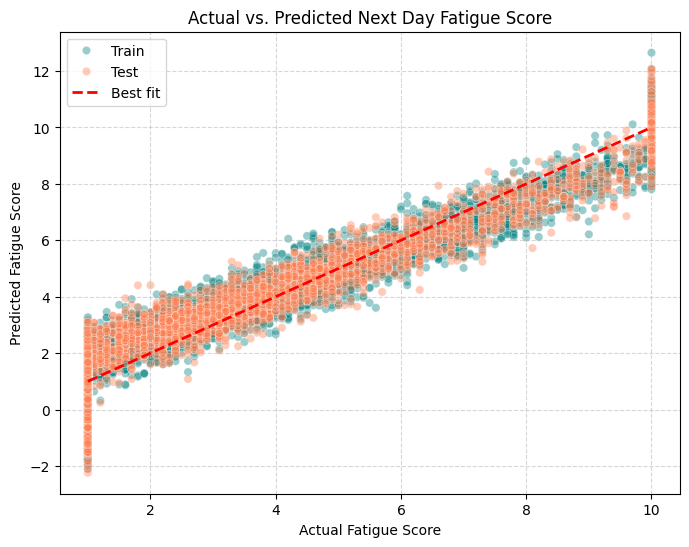

In [9]:
# visualise


import seaborn as sns

# training set
y_train_pred = model.predict(X_train)

# dataframe for actual and pred.d values for the training dataset
train_results = pd.DataFrame({
    'Actual Fatigue Score': y_train.values.flatten(),
    'Predicted Fatigue Score': y_train_pred.flatten(),
    'Dataset': 'Train'
})

# dataframe for actual and predicted values for the testing dataset
test_results = pd.DataFrame({
    'Actual Fatigue Score': y_test.values.flatten(),
    'Predicted Fatigue Score': y_pred.flatten(),
    'Dataset': 'Test'
})

# combine training and testing results
results_df = pd.concat([train_results, test_results], ignore_index=True)

print(f"R-squared (R² Score) on Test Set: {r2:.4f}")

plt.figure(figsize=(8, 6))
sns.scatterplot(
    x='Actual Fatigue Score',
    y='Predicted Fatigue Score',
    hue='Dataset',
    data=results_df,
    alpha=0.4,
    palette={'Train': 'teal', 'Test': 'coral'}
)

# line of best fit
plt.plot([results_df['Actual Fatigue Score'].min(), results_df['Actual Fatigue Score'].max()],
         [results_df['Actual Fatigue Score'].min(), results_df['Actual Fatigue Score'].max()],
         color='red', linestyle='--', linewidth=2, label='Best fit')

plt.title('Actual vs. Predicted Next Day Fatigue Score')
plt.xlabel('Actual Fatigue Score')
plt.ylabel('Predicted Fatigue Score')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [10]:

# to minimise the target (next_day_fatigue_score)
# next_day_fatigue_score = intercept + sum(Coef_i * Normalized_Feature_i)
# for a positive coefficient we want the min value
# + for a negative coefficient, we want the max value

optimal_features_normalized = {}
optimal_features_raw = {}

for col in feature_cols:
    col_min = df[col].min()
    col_max = df[col].max()


    mean = X_means[col]
    std = X_stds[col]

    coef = coefficients.loc[coefficients['Feature'] == col, 'Coefficient'].values[0]

    if coef > 0:
        opt_val_raw = col_min
    else:
        opt_val_raw = col_max

    optimal_features_raw[col] = opt_val_raw
    optimal_features_normalized[col] = (opt_val_raw - mean) / std

opt_norm_vector = np.array([optimal_features_normalized[col] for col in feature_cols]).reshape(1, -1)
opt_fatigue_score = model.predict(opt_norm_vector)[0][0]


optimal_df = pd.DataFrame({
    'Feature': feature_cols,
    'Coefficient': [coefficients.loc[coefficients['Feature'] == col, 'Coefficient'].values[0] for col in feature_cols],
    'Dataset Min': [df[col].min() for col in feature_cols],
    'Dataset Max': [df[col].max() for col in feature_cols],
    'Optimal Value': [optimal_features_raw[col] for col in feature_cols]
})

print(f"Theoretical Minimum Predicted Fatigue Score: {opt_fatigue_score:.4f}\n")
display(optimal_df)

Theoretical Minimum Predicted Fatigue Score: -2.9321



/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


,Feature,Coefficient,Dataset Min,Dataset Max,Optimal Value
0,bedtime_phone_minutes,0.206225,1.0,180.0,1.0
1,screen_brightness_pct,0.106811,10.0,100.0,10.0
2,blue_light_filter_active,-0.071870,0.0,1.0,1.0
3,caffeine_post_5pm_mg,0.200112,0.0,250.0,0.0
4,physical_activity_min,0.011425,0.0,112.0,0.0
5,sleep_latency_min,0.540865,6.0,123.3,6.0
6,total_sleep_hours,-1.389849,3.2,9.8,9.8
7,deep_sleep_pct,-0.200993,8.1,28.0,28.0
8,rem_sleep_pct,-0.007518,9.6,27.0,27.0
9,morning_alarm_snoozes,0.637744,0.0,7.0,0.0


To guarantee a Fatigue Score of 1.0: You only need a minimum of 5.71 hours of sleep
To guarantee a Fatigue Score of 2.0: You only need a minimum of 4.67 hours of sleep
To guarantee a Fatigue Score of 3.0: You only need a minimum of 3.63 hours of sleep
To guarantee a Fatigue Score of 4.0: You only need a minimum of 3.20 hours of sleep
To guarantee a Fatigue Score of 5.0: You only need a minimum of 3.20 hours of sleep

All fatigue scores beyond 4 only need a minimum of 3.2 hours.



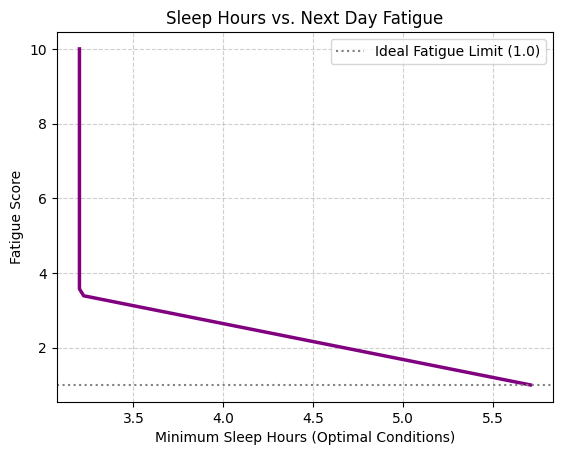

In [11]:
# if all values are optimal, how many hours of sleep are needed to
# theoretically have a fatigue score of 1?

intercept = model.intercept_[0]

other_features_contribution = 0.0
for col in feature_cols:
    if col == 'total_sleep_hours':
        continue # skip

    # get from previous cell
    mean = X_means[col]
    std = X_stds[col]
    coef = coefficients.loc[coefficients['Feature'] == col, 'Coefficient'].values[0]
    opt_raw = optimal_features_raw[col]

    opt_norm = (opt_raw - mean) / std
    other_features_contribution += coef * opt_norm

# fatigue_score = intercept + other_features_contribution + (coef_sleep * normalised_sleep)
sleep_coef = coefficients.loc[coefficients['Feature'] == 'total_sleep_hours', 'Coefficient'].values[0]
sleep_mean = X_means['total_sleep_hours']
sleep_std = X_stds['total_sleep_hours']

# sleep hours for target fatigue scores (1 - 10)
target_fatigue_scores = np.linspace(1.0, 10.0, 50)
required_sleep_hours = []

for target_f in target_fatigue_scores:
    # normalised sleep:
    # target_f = intercept + other_features_contribution + sleep_coef * norm_sleep
    norm_sleep = (target_f - intercept - other_features_contribution) / sleep_coef
    # convert back to raw sleep hours: raw_sleep = norm_sleep * std + mean
    raw_sleep = norm_sleep * sleep_std + sleep_mean

    # clip raw_sleep to the actual limits in our dataset so it doesn't go below min sleep hours
    raw_sleep_clipped = np.clip(raw_sleep, df['total_sleep_hours'].min(), df['total_sleep_hours'].max())
    required_sleep_hours.append(raw_sleep_clipped)

tradeoff_df = pd.DataFrame({
    'Target Fatigue Score': target_fatigue_scores,
    'Minimum Sleep Hours Required': required_sleep_hours
})

landmarks = [1.0, 2.0, 3.0, 4.0, 5.0]
for f in landmarks:
    norm_s = (f - intercept - other_features_contribution) / sleep_coef
    raw_s = np.clip(norm_s * sleep_std + sleep_mean, df['total_sleep_hours'].min(), df['total_sleep_hours'].max())
    print(f"To guarantee a Fatigue Score of {f:.1f}: You only need a minimum of {raw_s:.2f} hours of sleep")
print(f"\nAll fatigue scores beyond 4 only need a minimum of 3.2 hours.\n")

# graph
plt.plot(tradeoff_df['Minimum Sleep Hours Required'], tradeoff_df['Target Fatigue Score'], color='purple', linewidth=2.5)
plt.title('Sleep Hours vs. Next Day Fatigue')
plt.xlabel('Minimum Sleep Hours (Optimal Conditions)')
plt.ylabel('Fatigue Score')
plt.grid(True, linestyle='--', alpha=0.6)
plt.axhline(1.0, color='gray', linestyle=':', label='Ideal Fatigue Limit (1.0)')
plt.legend()
plt.show()

Under average conditions:
To guarantee a Fatigue Score of 1.0: You need a minimum of 9.19 hours of sleep
To guarantee a Fatigue Score of 2.0: You need a minimum of 8.14 hours of sleep
To guarantee a Fatigue Score of 3.0: You need a minimum of 7.10 hours of sleep
To guarantee a Fatigue Score of 4.0: You need a minimum of 6.06 hours of sleep
To guarantee a Fatigue Score of 5.0: You need a minimum of 5.02 hours of sleep
To guarantee a Fatigue Score of 6.0: You need a minimum of 3.98 hours of sleep
To guarantee a Fatigue Score of 7.0: You need a minimum of 3.20 hours of sleep
To guarantee a Fatigue Score of 8.0: You need a minimum of 3.20 hours of sleep
To guarantee a Fatigue Score of 9.0: You need a minimum of 3.20 hours of sleep
To guarantee a Fatigue Score of 10.0: You need a minimum of 3.20 hours of sleep




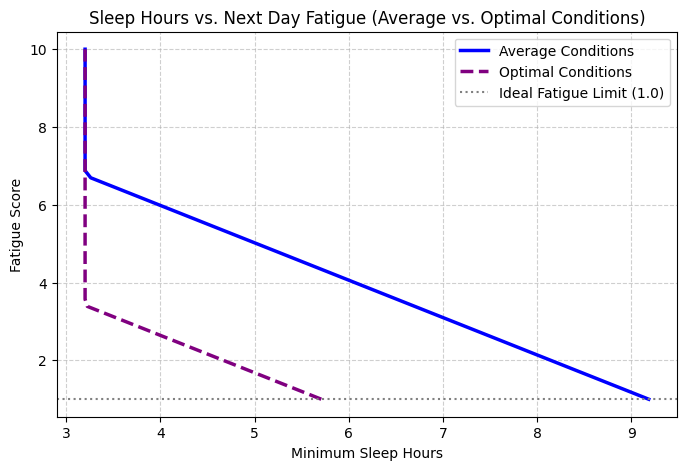

In [12]:
# sleep hours for target fatigue scores (1 - 10) under AVERAGE conditions
intercept = model.intercept_[0]

average_features_contribution = 0.0
for col in feature_cols:
    if col == 'total_sleep_hours':
        continue
    # the mean of a z-score normalized feature is exactly 0.0
    average_features_contribution += 0.0

sleep_coef = coefficients.loc[coefficients['Feature'] == 'total_sleep_hours', 'Coefficient'].values[0]
sleep_mean = X_means['total_sleep_hours']
sleep_std = X_stds['total_sleep_hours']

target_fatigue_scores = np.linspace(1.0, 10.0, 50)
required_sleep_hours_avg = []

for target_f in target_fatigue_scores:
    # target_f = intercept + average_features_contribution + sleep_coef * norm_sleep
    norm_sleep = (target_f - intercept - average_features_contribution) / sleep_coef
    raw_sleep = norm_sleep * sleep_std + sleep_mean

    # clip to actual limits in dataset
    raw_sleep_clipped = np.clip(raw_sleep, df['total_sleep_hours'].min(), df['total_sleep_hours'].max())
    required_sleep_hours_avg.append(raw_sleep_clipped)

tradeoff_avg_df = pd.DataFrame({
    'Target Fatigue Score': target_fatigue_scores,
    'Minimum Sleep Hours Required': required_sleep_hours_avg
})

print("Under average conditions:")
for f in [1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0]:
    norm_s = (f - intercept - average_features_contribution) / sleep_coef
    raw_s = np.clip(norm_s * sleep_std + sleep_mean, df['total_sleep_hours'].min(), df['total_sleep_hours'].max())
    print(f"To guarantee a Fatigue Score of {f:.1f}: You need a minimum of {raw_s:.2f} hours of sleep")
print(f"\n")

# graph
plt.figure(figsize=(8, 5))
plt.plot(tradeoff_avg_df['Minimum Sleep Hours Required'], tradeoff_avg_df['Target Fatigue Score'], color='blue', linewidth=2.5, label='Average Conditions')
plt.plot(tradeoff_df['Minimum Sleep Hours Required'], tradeoff_df['Target Fatigue Score'], color='purple', linewidth=2.5, linestyle='--', label='Optimal Conditions')
plt.title('Sleep Hours vs. Next Day Fatigue (Average vs. Optimal Conditions)')
plt.xlabel('Minimum Sleep Hours')
plt.ylabel('Fatigue Score')
plt.grid(True, linestyle='--', alpha=0.6)
plt.axhline(1.0, color='gray', linestyle=':', label='Ideal Fatigue Limit (1.0)')
plt.legend()
plt.show()

---

# Random forest

Random Forest - Mean Squared Error (MSE): 0.3637
Random Forest - R-squared (R2 Score): 0.9495


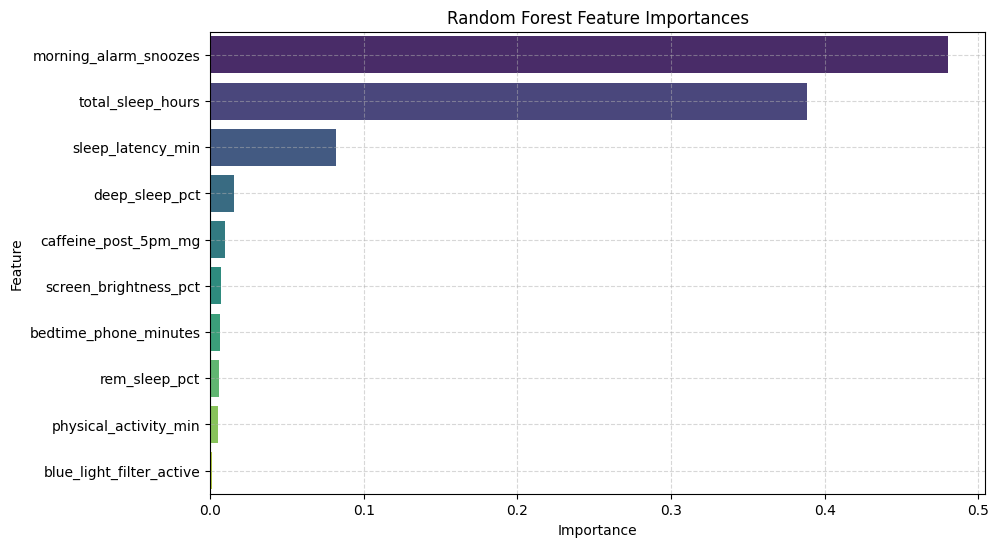

In [13]:
from sklearn.ensemble import RandomForestRegressor

# train model
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train.values.ravel())

# predictions on test set
y_pred_rf = rf_model.predict(X_test)

# evaluation metrics
mse_rf = mean_squared_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print(f"Random Forest - Mean Squared Error (MSE): {mse_rf:.4f}")
print(f"Random Forest - R-squared (R2 Score): {r2_rf:.4f}")

# plot feature importances
importances = rf_model.feature_importances_
feature_importances = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# graph
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importances, hue='Feature', palette='viridis', legend=False)
plt.title('Random Forest Feature Importances')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()